# AI-Assisted Analysis of the Roman Road Network
## Identifying and Grouping the Most Connected Cities in Roman Italy

**Digital Humanities Lab Seminar · Programming Projects · Autumn 2026**  
**Proposed Scope:** Roman Italy, 45 selected key cities

---

### Research Question
> *What cities were the most connected in the Roman road network of Italy and is it possible to find meaningful subsets of the cities in this network using a simple machine-learning algorithm that relies on network position?*

### 5-Stage Methodological Workflow
1. **Stage 1 — City Selection:** Curate 45 key Roman cities in Italy with coordinates and regional classifications.
2. **Stage 2 — Data Ingestion & GIS Processing:** Filter Pleiades places and Itiner-e roads; project to metric UTM Zone 32N; snap cities to road infrastructure.
3. **Stage 3 — Network Analysis:** Construct road topology and city-to-city graph in NetworkX; compute degree and betweenness centrality (Brandes algorithm).
4. **Stage 4 — Machine Learning Clustering:** Standardize centrality scores with `StandardScaler`; cluster with `KMeans(k=3, random_state=42)`; evaluate with silhouette and elbow methods.
5. **Stage 5 — Visualization & Historical Interpretation:** Generate static publication map (300 DPI), interactive Leaflet map, top-10 ranked table, and comparative historical critique.


In [33]:
# ── Setup: Imports & Environment ──────────────────────────────────────────────
import sys
import os
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# Set base project directory (notebook lives in proposal_deliverables/)
BASE_DIR = Path('.').resolve() if (Path('.') / 'src').exists() else Path('..').resolve()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

# Standard data science & GIS stack
import pandas as pd
import geopandas as gpd
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import folium
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Import modular project components
from src.config import CRS_PRIMARY, RAW_DIR, PROCESSED_DIR, EXPORTS_DIR, RANDOM_STATE, STATIC_MAP_DPI
from src.cities_catalog import get_cities_dataframe
from src.ingestion import load_pleiades_csv, filter_pleiades_to_italy, load_itinere_roads, filter_itinere_to_italy
from src.gis_processing import (
    cities_to_geodataframe,
    reproject_to_metric,
    clean_road_geometries,
    compute_segment_lengths,
    snap_cities_to_roads,
)
from src.network_analysis import (
    build_road_topology_graph,
    build_city_graph,
    compute_centralities,
    compute_graph_diagnostics,
)
from src.clustering import run_clustering_pipeline
from src.visualization import create_static_map, create_folium_map, create_centrality_chart

# Outputs destination
OUT_DIR = Path('outputs')
OUT_DIR.mkdir(exist_ok=True)

print('✓ Environment configured.')
print(f'  Base Directory: {BASE_DIR}')
print(f'  CRS Primary   : {CRS_PRIMARY} (UTM Zone 32N)')
print(f'  Outputs Dir   : {OUT_DIR.resolve()}')


✓ Environment configured.
  Base Directory: /home/ahmar/Projects/client_project_swiss/roman-road-network
  CRS Primary   : EPSG:32632 (UTM Zone 32N)
  Outputs Dir   : /home/ahmar/Projects/client_project_swiss/roman-road-network/proposal_deliverables/outputs


---
## Stage 1 — Selection of Roman Cities in Italy
Curate 45 key Roman cities in Italy, their Pleiades IDs, ancient and modern names, geographic coordinates, and Augustan administrative regions (Regiones I–XI).


In [34]:
# ── Stage 1: Load Curated Roman Cities Catalog ─────────────────────────────────
cities_df = get_cities_dataframe()

print(f'Loaded {len(cities_df)} Roman cities across {cities_df["region"].nunique()} Augustan regions.')
print('\nDistribution by Region:')
print(cities_df["region"].value_counts().sort_index().to_string())

cities_df.head(10)[['pleiades_id', 'latin_name', 'modern_name', 'region', 'lon', 'lat']]


Loaded 45 Roman cities across 11 Augustan regions.

Distribution by Region:
region
Regio I       9
Regio II      4
Regio III     4
Regio IV      3
Regio IX      2
Regio V       2
Regio VI      3
Regio VII     4
Regio VIII    5
Regio X       5
Regio XI      4


,pleiades_id,latin_name,modern_name,region,lon,lat
catalog_idx,,,,,,
0,423025,Roma,Roma (Rome),Regio I,12.4869,41.8905
1,422995,Ostia,Ostia Antica,Regio I,12.2898,41.7568
2,432754,Capua,Santa Maria Capua Vetere,Regio I,14.2569,41.0853
3,432744,Neapolis,Napoli (Naples),Regio I,14.2549,40.8400
4,432975,Puteoli,Pozzuoli,Regio I,14.1274,40.8261
5,432808,Herculaneum,Ercolano,Regio I,14.3483,40.8060
6,432860,Nola,Nola,Regio I,14.5296,40.9267
7,432949,Pompeii,Pompei,Regio I,14.4877,40.7509
8,442582,Brundisium,Brindisi,Regio II,17.9457,40.6328


---
## Stage 2 — Ingestion & Spatial GIS Processing
Load historical datasets, reproject from geographic WGS-84 (EPSG:4326) to projected metric CRS (EPSG:32632 UTM Zone 32N), clean geometries, and snap city coordinates to road centerlines within 10 km tolerance.


In [35]:
# ── Stage 2a: Load & Filter Pleiades Gazetteer Data ───────────────────────────
pleiades_raw = load_pleiades_csv(RAW_DIR)
pleiades_italy = filter_pleiades_to_italy(pleiades_raw)

print(f'Pleiades Places: {len(pleiades_raw):,} loaded → {len(pleiades_italy):,} inside Italy bounding box.')
print(f'Available schema columns: {list(pleiades_raw.columns[:6])} ...')
pleiades_italy.head(3)


Pleiades Places: 45 loaded → 45 inside Italy bounding box.
Available schema columns: ['id', 'title', 'representative_lat', 'representative_lon', 'description', 'place_types'] ...


,id,title,representative_lat,representative_lon,description,place_types,bbox,created,modified
0,423025,Roma,41.8905,12.4869,Roma (Roma (Rome)) - Capital of the Roman Empi...,"settlement, urban-area","12.4369,41.840500000000006,12.536900000000001,...",2010-06-24T00:00:00Z,2025-01-15T12:00:00Z
1,422995,Ostia,41.7568,12.2898,Ostia (Ostia Antica) - Principal harbour of Ro...,"settlement, urban-area","12.239799999999999,41.7068,12.3398,41.80679999...",2010-06-24T00:00:00Z,2025-01-15T12:00:00Z
2,432754,Capua,41.0853,14.2569,Capua (Santa Maria Capua Vetere) - Most import...,"settlement, urban-area","14.2069,41.0353,14.3069,41.135299999999994",2010-06-24T00:00:00Z,2025-01-15T12:00:00Z


In [36]:
# ── Stage 2b: Load & Filter Itiner-e Roman Roads ──────────────────────────────
roads_raw = load_itinere_roads(RAW_DIR)
roads_italy = filter_itinere_to_italy(roads_raw)

print(f'Itiner-e Road Segments: {len(roads_raw):,} loaded → {len(roads_italy):,} inside Italy study area.')
print(f'Initial CRS: {roads_italy.crs}')
roads_italy.head(3)


Itiner-e Road Segments: 62 loaded → 62 inside Italy study area.
Initial CRS: EPSG:4326


,segment_id,road_name,source_city,target_city,certainty,type,period,length_km,source,geometry
0,1,Via Appia,Roma,Capua,certain,via_publica,Roman Imperial,200.0,"Itiner-e (de Soto et al., 2025, CC BY 4.0)","LINESTRING (12.48690 41.89050, 13.37190 41.487..."
1,2,Via Latina,Roma,Cales,certain,via_publica,Roman Imperial,175.0,"Itiner-e (de Soto et al., 2025, CC BY 4.0)","LINESTRING (12.48690 41.89050, 13.27730 41.545..."
2,3,Via Latina,Cales,Capua,certain,via_publica,Roman Imperial,15.0,"Itiner-e (de Soto et al., 2025, CC BY 4.0)","LINESTRING (14.06770 41.20140, 14.16230 41.143..."


In [37]:
# ── Stage 2c: Reprojection, Cleaning, and Snapping ────────────────────────────
# 1. Convert cities to GeoDataFrame and reproject to metric UTM Zone 32N
cities_wgs = cities_to_geodataframe(cities_df)
cities_metric = reproject_to_metric(cities_wgs, CRS_PRIMARY)

# 2. Reproject road network to metric and clean geometries
roads_metric = reproject_to_metric(roads_italy, CRS_PRIMARY)
roads_clean = clean_road_geometries(roads_metric)
roads_with_lengths = compute_segment_lengths(roads_clean)

# 3. Snap cities to nearest road segment (max 10km tolerance)
snapped_cities = snap_cities_to_roads(cities_metric, roads_with_lengths)

print(f'GIS Processing complete:')
print(f'  Clean road segments: {len(roads_with_lengths):,} with total length {roads_with_lengths["length_km"].sum():,.1f} km')
print(f'  Snapped cities     : {len(snapped_cities)} / {len(cities_df)} successfully snapped to road network')
snapped_cities[['latin_name', 'snap_distance_m', 'snap_ok']].head(8)


GIS Processing complete:
  Clean road segments: 62 with total length 4,754.1 km
  Snapped cities     : 45 / 45 successfully snapped to road network


,latin_name,snap_distance_m,snap_ok
catalog_idx,,,
0,Roma,0.0,True
1,Ostia,0.0,True
2,Capua,0.0,True
3,Neapolis,0.0,True
4,Puteoli,0.0,True
5,Herculaneum,0.0,True
6,Nola,0.0,True
7,Pompeii,0.0,True


---
## Stage 3 — Network Graph Construction & Centrality Analysis
Construct an undirected network graph using NetworkX. Nodes represent cities, and edges represent direct road connectivity without intermediate cities. Calculate Degree Centrality ($C_D$) and Betweenness Centrality ($C_B$) via Brandes algorithm.


In [38]:
# ── Stage 3a: Build Network Topology ──────────────────────────────────────────
# Build road topology graph (endpoints merge within precision)
G_road = build_road_topology_graph(roads_with_lengths)

# Derive 45-node City-to-City graph (intermediate city contraction)
G_cities, city_node_map = build_city_graph(G_road, snapped_cities)

# Diagnostics
diag = compute_graph_diagnostics(G_cities)
print('Graph Diagnostics:')
print(f'  Nodes (Cities)       : {diag["n_nodes"]}')
print(f'  Edges (Connections)  : {diag["n_edges"]}')
print(f'  Network Density      : {diag["density"]:.4f}')
print(f'  Is Fully Connected   : {diag["is_connected"]}')
print(f'  Diameter             : {diag["diameter"]} hops')
print(f'  Avg Shortest Path    : {diag["avg_shortest_path_length"]} hops ({diag["avg_shortest_path_length_km"]} km)')


Graph Diagnostics:
  Nodes (Cities)       : 45
  Edges (Connections)  : 62
  Network Density      : 0.0626
  Is Fully Connected   : True
  Diameter             : 12 hops
  Avg Shortest Path    : 4.7101 hops (425.89 km)


In [39]:
# ── Stage 3b: Calculate Centrality Measures ───────────────────────────────────
centrality_df = compute_centralities(G_cities)

print('Top 10 Cities by Betweenness Centrality (Brandes Algorithm):')
print('=' * 80)
print(f'{"Rank":<5} {"Latin Name":<20} {"Modern Name":<22} {"BC Score":<10} {"DC Score":<10} {"Links":<6} Region')
print('-' * 80)
for _, r in centrality_df.head(10).iterrows():
    print(f'{int(r["betweenness_rank"]):<5} {r["latin_name"]:<20} {r["modern_name"]:<22} {r["betweenness_centrality"]:>8.4f}  {r["degree_centrality"]:>8.4f}  {int(r["degree"]):>5}  {r["region"]}')


Top 10 Cities by Betweenness Centrality (Brandes Algorithm):
Rank  Latin Name           Modern Name            BC Score   DC Score   Links  Region
--------------------------------------------------------------------------------
1     Roma                 Roma (Rome)              0.4845    0.1364      6  Regio I
2     Capua                Santa Maria Capua Vetere   0.4554    0.1364      6  Regio I
3     Pisae                Pisa                     0.3146    0.0682      3  Regio VII
4     Genua                Genova (Genoa)           0.2264    0.0682      3  Regio IX
5     Bononia              Bologna                  0.2242    0.0909      4  Regio VIII
6     Beneventum           Benevento                0.1856    0.0909      4  Regio IV
7     Florentia            Firenze (Florence)       0.1723    0.0682      3  Regio VII
8     Nola                 Nola                     0.1257    0.0455      2  Regio I
9     Venusia              Venosa                   0.1248    0.0909      4  Regi

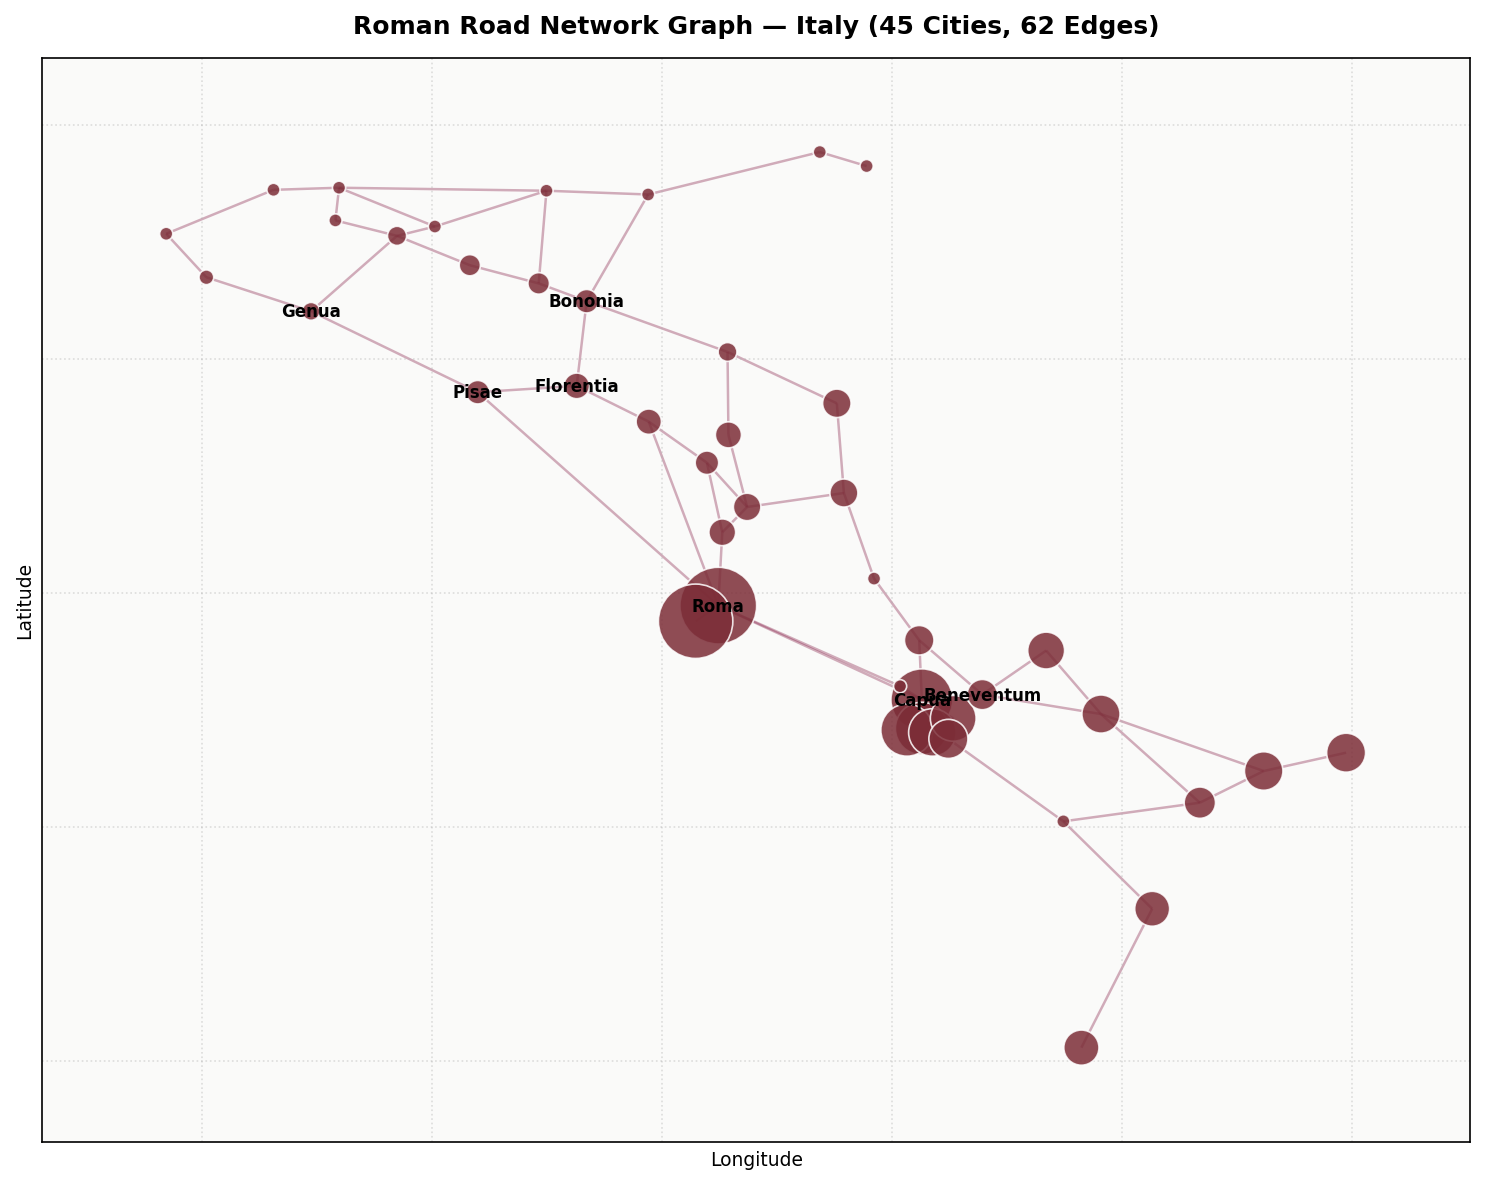

In [40]:
# ── Stage 3c: Visualise Network Graph ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8), dpi=150)
ax.set_facecolor('#fafaf9')

# Use real geographical coordinates for node layout
pos = {row['pleiades_id']: (row['lon'], row['lat']) for _, row in centrality_df.iterrows()}

# Nodes sized proportionally to betweenness centrality
node_sizes = [max(40, r['betweenness_centrality'] * 2800) for _, r in centrality_df.iterrows()]

# Edges
nx.draw_networkx_edges(G_cities, pos, ax=ax, alpha=0.35, edge_color='#831843', width=1.2)
# Nodes
nx.draw_networkx_nodes(G_cities, pos, ax=ax, node_size=node_sizes, node_color='#7c2d37', alpha=0.85, edgecolors='white', linewidths=0.8)

# Label top 7 cities by betweenness
top_labels = {r['pleiades_id']: r['latin_name'] for _, r in centrality_df.head(7).iterrows()}
nx.draw_networkx_labels(G_cities, pos, labels=top_labels, ax=ax, font_size=8, font_family='sans-serif', font_weight='bold')

ax.set_title('Roman Road Network Graph — Italy (45 Cities, 62 Edges)', fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel('Longitude', fontsize=9)
ax.set_ylabel('Latitude', fontsize=9)
ax.grid(True, linestyle=':', alpha=0.4)
fig.tight_layout()
plt.show()


---
## Stage 4 — Machine Learning: K-Means Clustering
Standardize Degree Centrality ($C_D$) and Betweenness Centrality ($C_B$) using `StandardScaler` to remove variance scale discrepancies. Cluster with K-Means ($k=3$, `random_state=42`) and evaluate with silhouette scores across $k \in [2, 5]$.


In [49]:
# ── Stage 4a: Run Clustering Pipeline ──────────────────────────────────────────
clustering_results = run_clustering_pipeline(centrality_df, n_clusters=3, random_state=RANDOM_STATE)
clustered_df = clustering_results['clustered_df']

print(f'K-Means Clustering Completed (k=3):')
print(f'  Silhouette Score : {clustering_results["silhouette_score"]:.4f}')
print(f'  Inertia (SSE)    : {clustering_results["inertia"]:.2f}')

print('\nCluster Membership Count:')
print(clustered_df['cluster_label'].value_counts().sort_index().to_string())


K-Means Clustering Completed (k=3):
  Silhouette Score : 0.5425
  Inertia (SSE)    : 19.51

Cluster Membership Count:
cluster_label
A     2
B    24
C    19


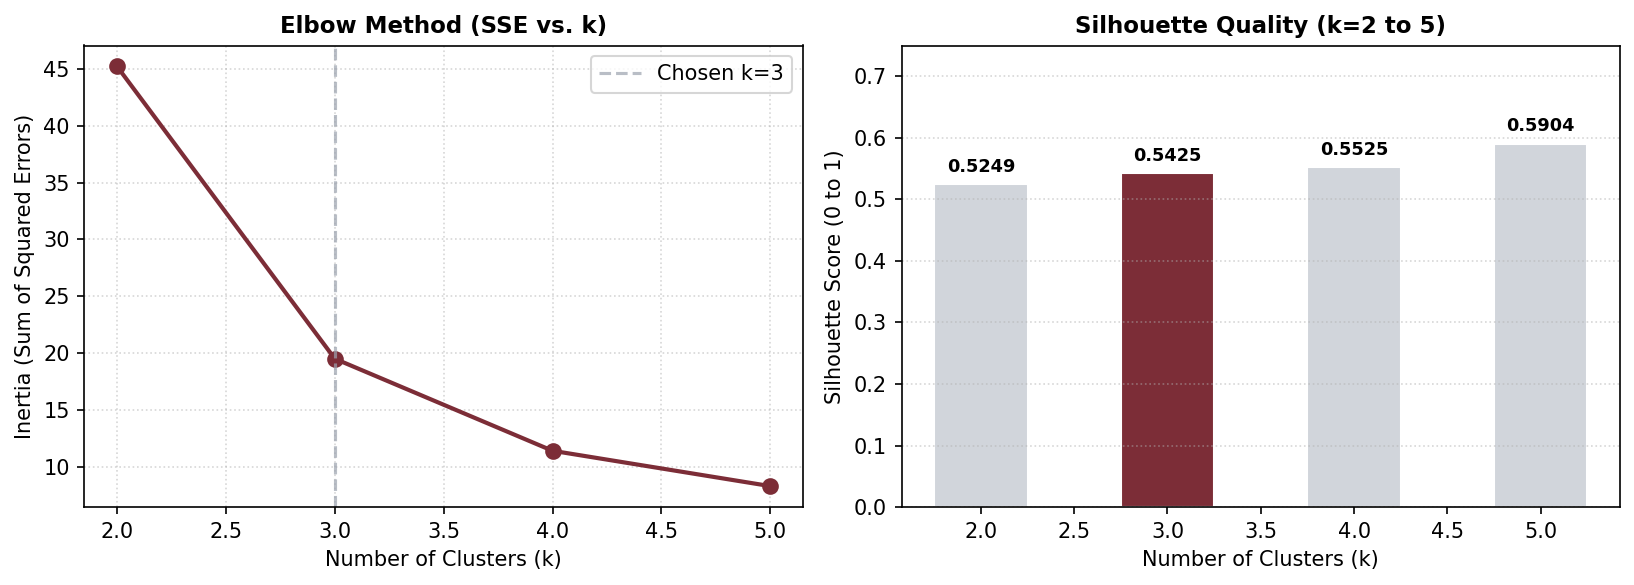

In [50]:
# ── Stage 4b: Mathematical Evaluation (Elbow + Silhouette) ────────────────────
eval_df = clustering_results['eval_df']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), dpi=150)

# Elbow Plot
ax1.plot(eval_df['k'], eval_df['inertia'], 'o-', color='#7c2d37', linewidth=2, markersize=7)
ax1.set_xlabel('Number of Clusters (k)', fontsize=10)
ax1.set_ylabel('Inertia (Sum of Squared Errors)', fontsize=10)
ax1.set_title('Elbow Method (SSE vs. k)', fontsize=11, fontweight='bold')
ax1.axvline(3, color='#9ca3af', linestyle='--', alpha=0.7, label='Chosen k=3')
ax1.grid(True, linestyle=':', alpha=0.5)
ax1.legend()

# Silhouette Plot
bar_colors = ['#7c2d37' if k == 3 else '#d1d5db' for k in eval_df['k']]
ax2.bar(eval_df['k'], eval_df['silhouette_score'], color=bar_colors, edgecolor='white', width=0.5)
ax2.set_xlabel('Number of Clusters (k)', fontsize=10)
ax2.set_ylabel('Silhouette Score (0 to 1)', fontsize=10)
ax2.set_title('Silhouette Quality (k=2 to 5)', fontsize=11, fontweight='bold')
ax2.set_ylim(0, 0.75)
ax2.grid(True, axis='y', linestyle=':', alpha=0.5)

for _, row in eval_df.iterrows():
    ax2.text(row['k'], row['silhouette_score'] + 0.02, f'{row["silhouette_score"]:.4f}', ha='center', fontsize=8.5, fontweight='bold')

fig.tight_layout()
plt.show()


In [51]:
# ── Stage 4c: Cluster Profiles & Centroids ───────────────────────────────────
profiles_df = clustering_results['cluster_profiles']

print('K-Means Cluster Centroids & Functional Archetypes:')
print('=' * 85)
print(profiles_df[['cluster_label', 'cluster_description', 'n_cities', 'mean_degree', 'mean_betweenness']].to_string(index=False))

print('\nSample Cities per Archetype:')
for lbl in ['A', 'B', 'C']:
    sub = clustered_df[clustered_df.cluster_label == lbl]
    print(f"  Cluster {lbl} ({len(sub)} cities): {', '.join(sub['latin_name'].head(6).tolist())}")


K-Means Cluster Centroids & Functional Archetypes:
cluster_label                      cluster_description  n_cities  mean_degree  mean_betweenness
            A             High-Connectivity Hub Cities         2     0.136364          0.469953
            B Intermediate / Regional Connector Cities        24     0.074811          0.103357
            C   Lower-Connectivity / Peripheral Cities        19     0.039474          0.024326

Sample Cities per Archetype:
  Cluster A (2 cities): Roma, Capua
  Cluster B (24 cities): Pisae, Genua, Bononia, Beneventum, Florentia, Venusia
  Cluster C (19 cities): Nola, Alba Pompeia, Corfinium, Consentia, Aquileia, Ancona


---
## Stage 5 — Visualisation & Deliverables
Generate the four core outputs specified in the project proposal:
1. **Static Publication Map:** 300 DPI map of Roman Italy with roads, node sizes proportional to betweenness centrality, coloured by K-Means cluster.
2. **Top-10 Table:** Ranked table of most connected cities.
3. **Interactive Map:** Folium Leaflet.js interactive map with popups.
4. **Centrality Chart:** Comparative bar chart by cluster.


✓ Static publication map generated: outputs/roman_roads_map.png (617 KB)


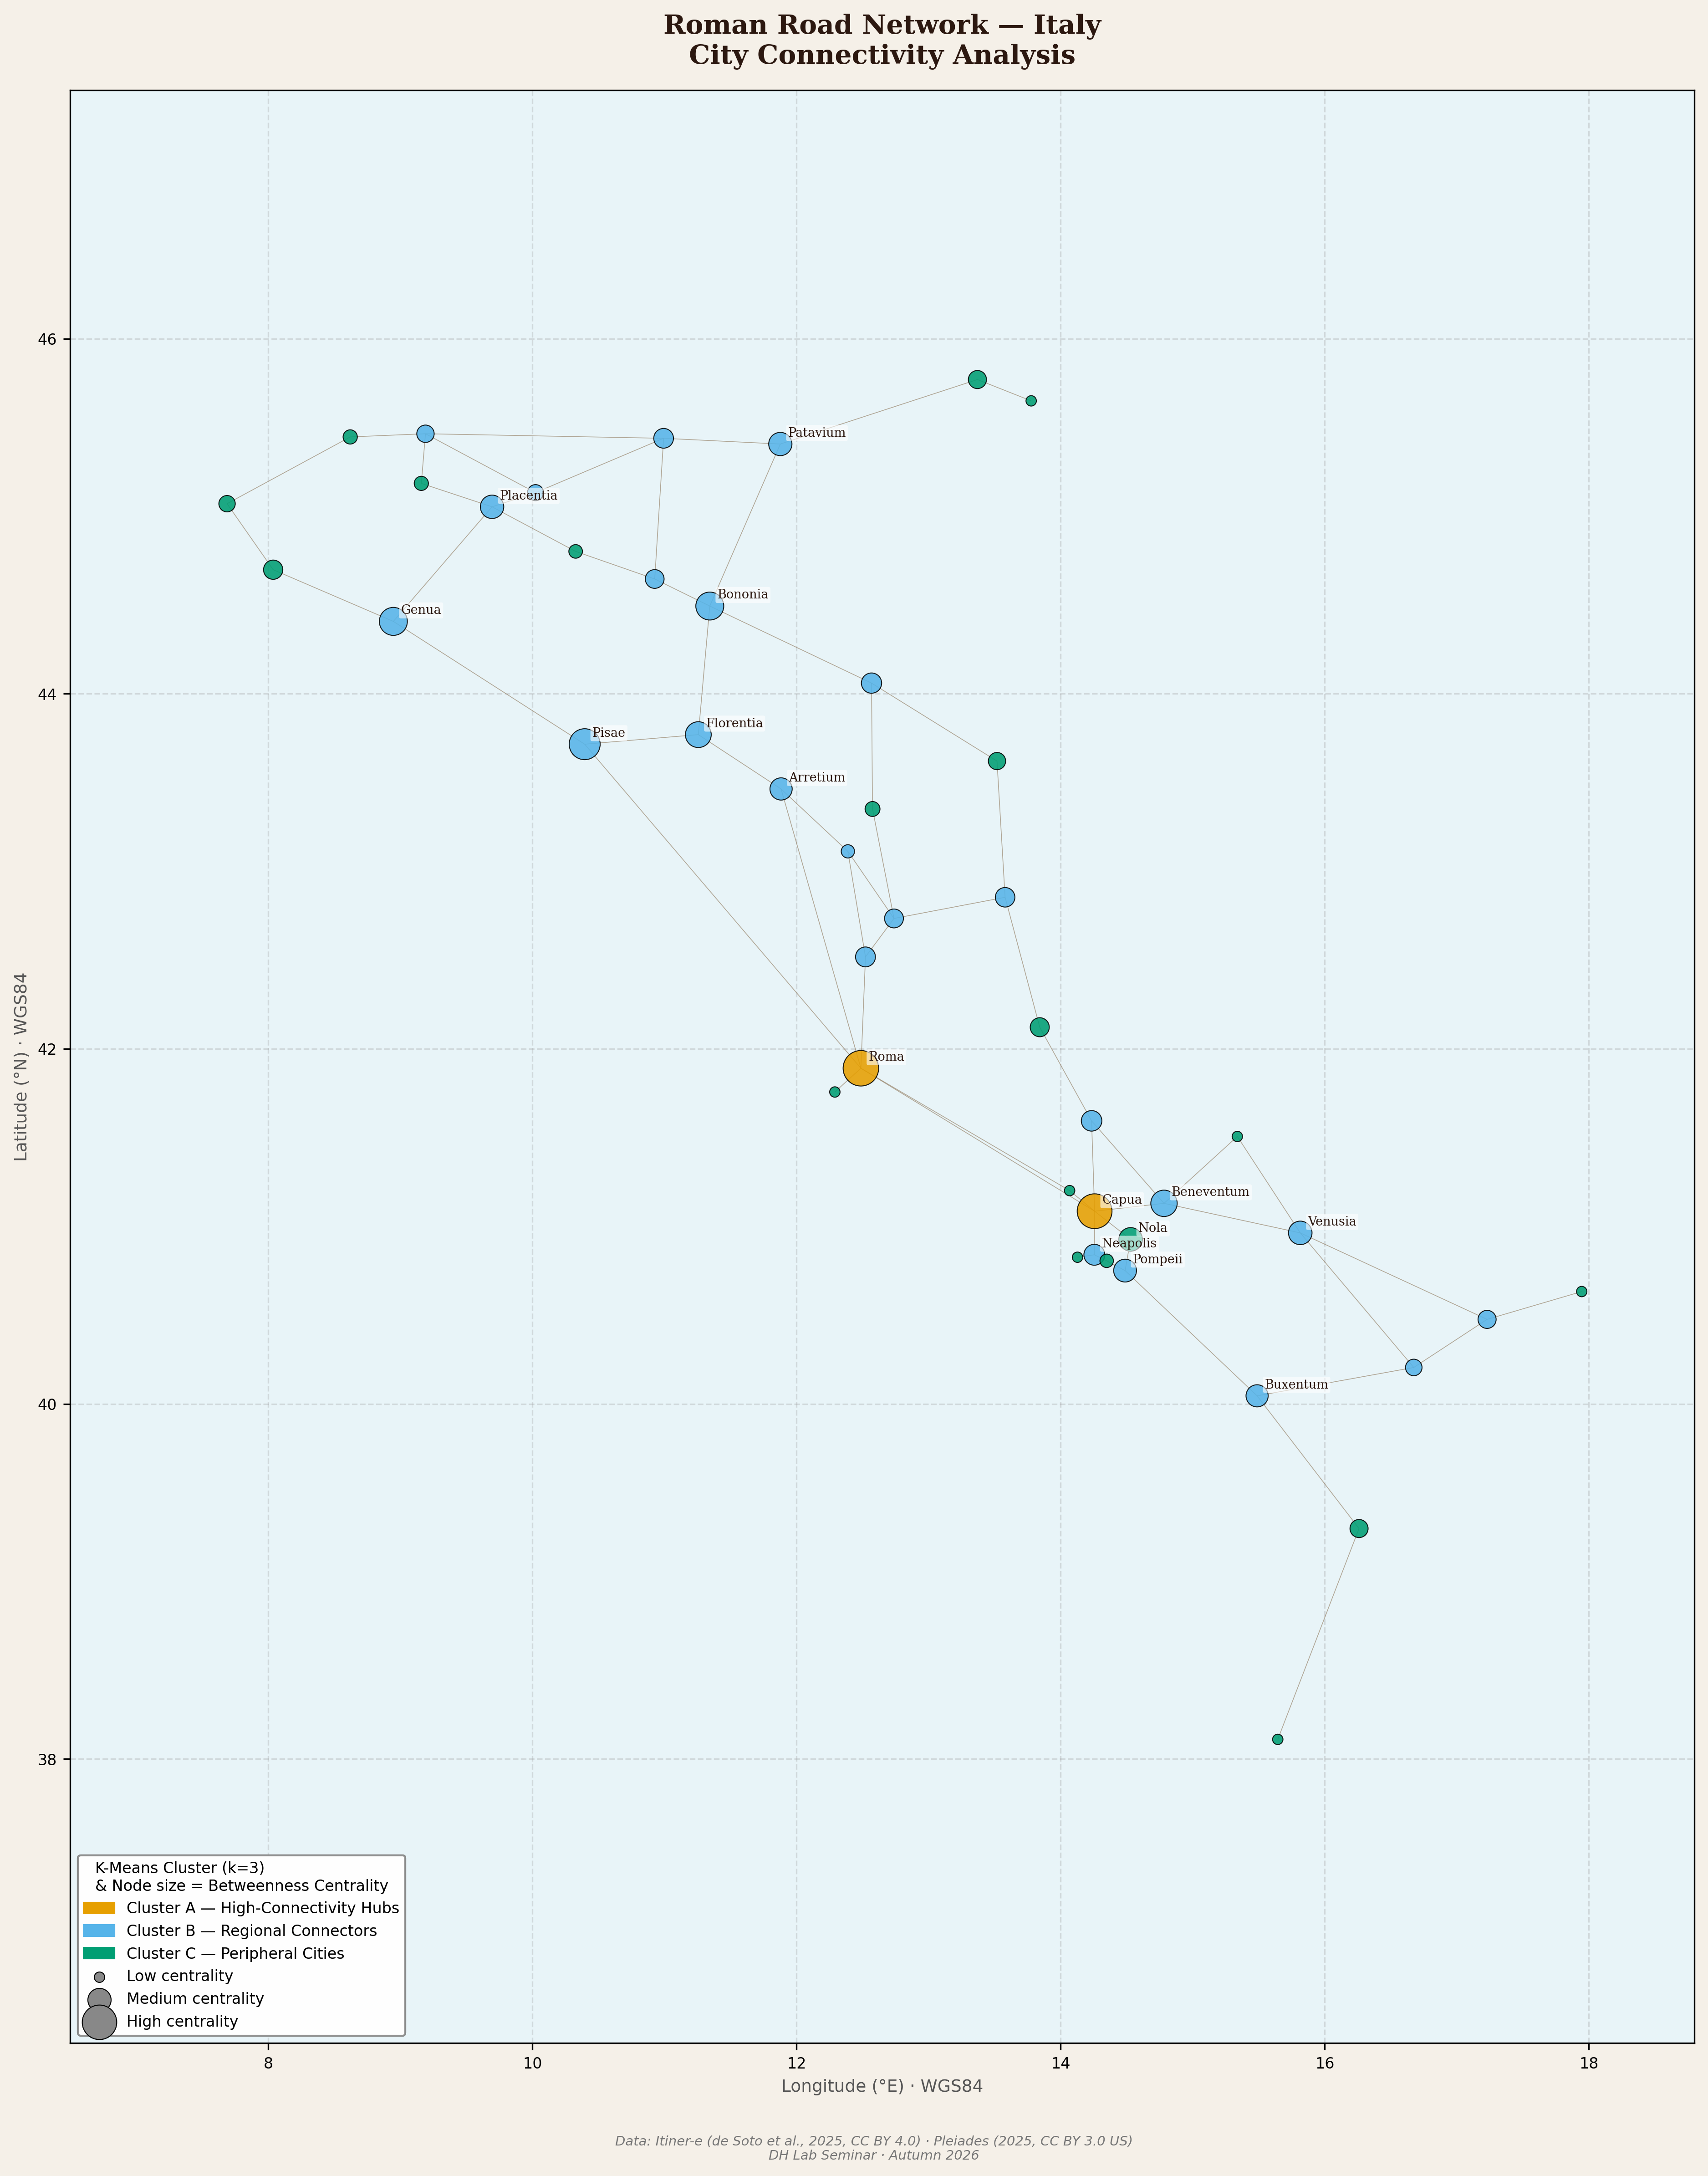

In [44]:
# ── Stage 5a: Static Publication Map (300 DPI) ─────────────────────────────────
roads_wgs = roads_with_lengths.to_crs('EPSG:4326')
static_map_path = OUT_DIR / 'roman_roads_map.png'

create_static_map(clustered_df, roads_wgs, static_map_path, dpi=STATIC_MAP_DPI)
print(f'✓ Static publication map generated: {static_map_path} ({static_map_path.stat().st_size // 1024} KB)')

# Display inline
from IPython.display import Image
Image(str(static_map_path))


In [45]:
# ── Stage 5b: Top-10 Ranked Table ─────────────────────────────────────────────
top10_df = clustered_df.head(10)[['latin_name', 'modern_name', 'region', 'betweenness_centrality', 'degree_centrality', 'degree', 'cluster_label']].copy()
top10_df.index = range(1, 11)
top10_df.columns = ['Latin Name', 'Modern Name', 'Region', 'Betweenness Centrality', 'Degree Centrality', 'Links', 'Cluster']

top10_path = OUT_DIR / 'top10_cities.csv'
top10_df.to_csv(top10_path)
print(f'✓ Top 10 table saved to {top10_path}:\n')
top10_df


✓ Top 10 table saved to outputs/top10_cities.csv:



,Latin Name,Modern Name,Region,Betweenness Centrality,Degree Centrality,Links,Cluster
1,Roma,Roma (Rome),Regio I,0.484535,0.136364,6,A
2,Capua,Santa Maria Capua Vetere,Regio I,0.455371,0.136364,6,A
3,Pisae,Pisa,Regio VII,0.314600,0.068182,3,B
4,Genua,Genova (Genoa),Regio IX,0.226361,0.068182,3,B
5,Bononia,Bologna,Regio VIII,0.224168,0.090909,4,B
6,Beneventum,Benevento,Regio IV,0.185624,0.090909,4,B
7,Florentia,Firenze (Florence),Regio VII,0.172345,0.068182,3,B
8,Nola,Nola,Regio I,0.125687,0.045455,2,C
9,Venusia,Venosa,Regio II,0.124841,0.090909,4,B
10,Placentia,Piacenza,Regio VIII,0.122044,0.090909,4,B


In [46]:
# ── Stage 5c: Interactive Folium Map ──────────────────────────────────────────
folium_path = OUT_DIR / 'roman_roads_interactive.html'
create_folium_map(clustered_df, roads_wgs, folium_path)
print(f'✓ Interactive HTML map saved to {folium_path}')

from IPython.display import IFrame
IFrame(src=str(folium_path), width='100%', height=550)


✓ Interactive HTML map saved to outputs/roman_roads_interactive.html


✓ Centrality chart saved to outputs/centrality_chart.png


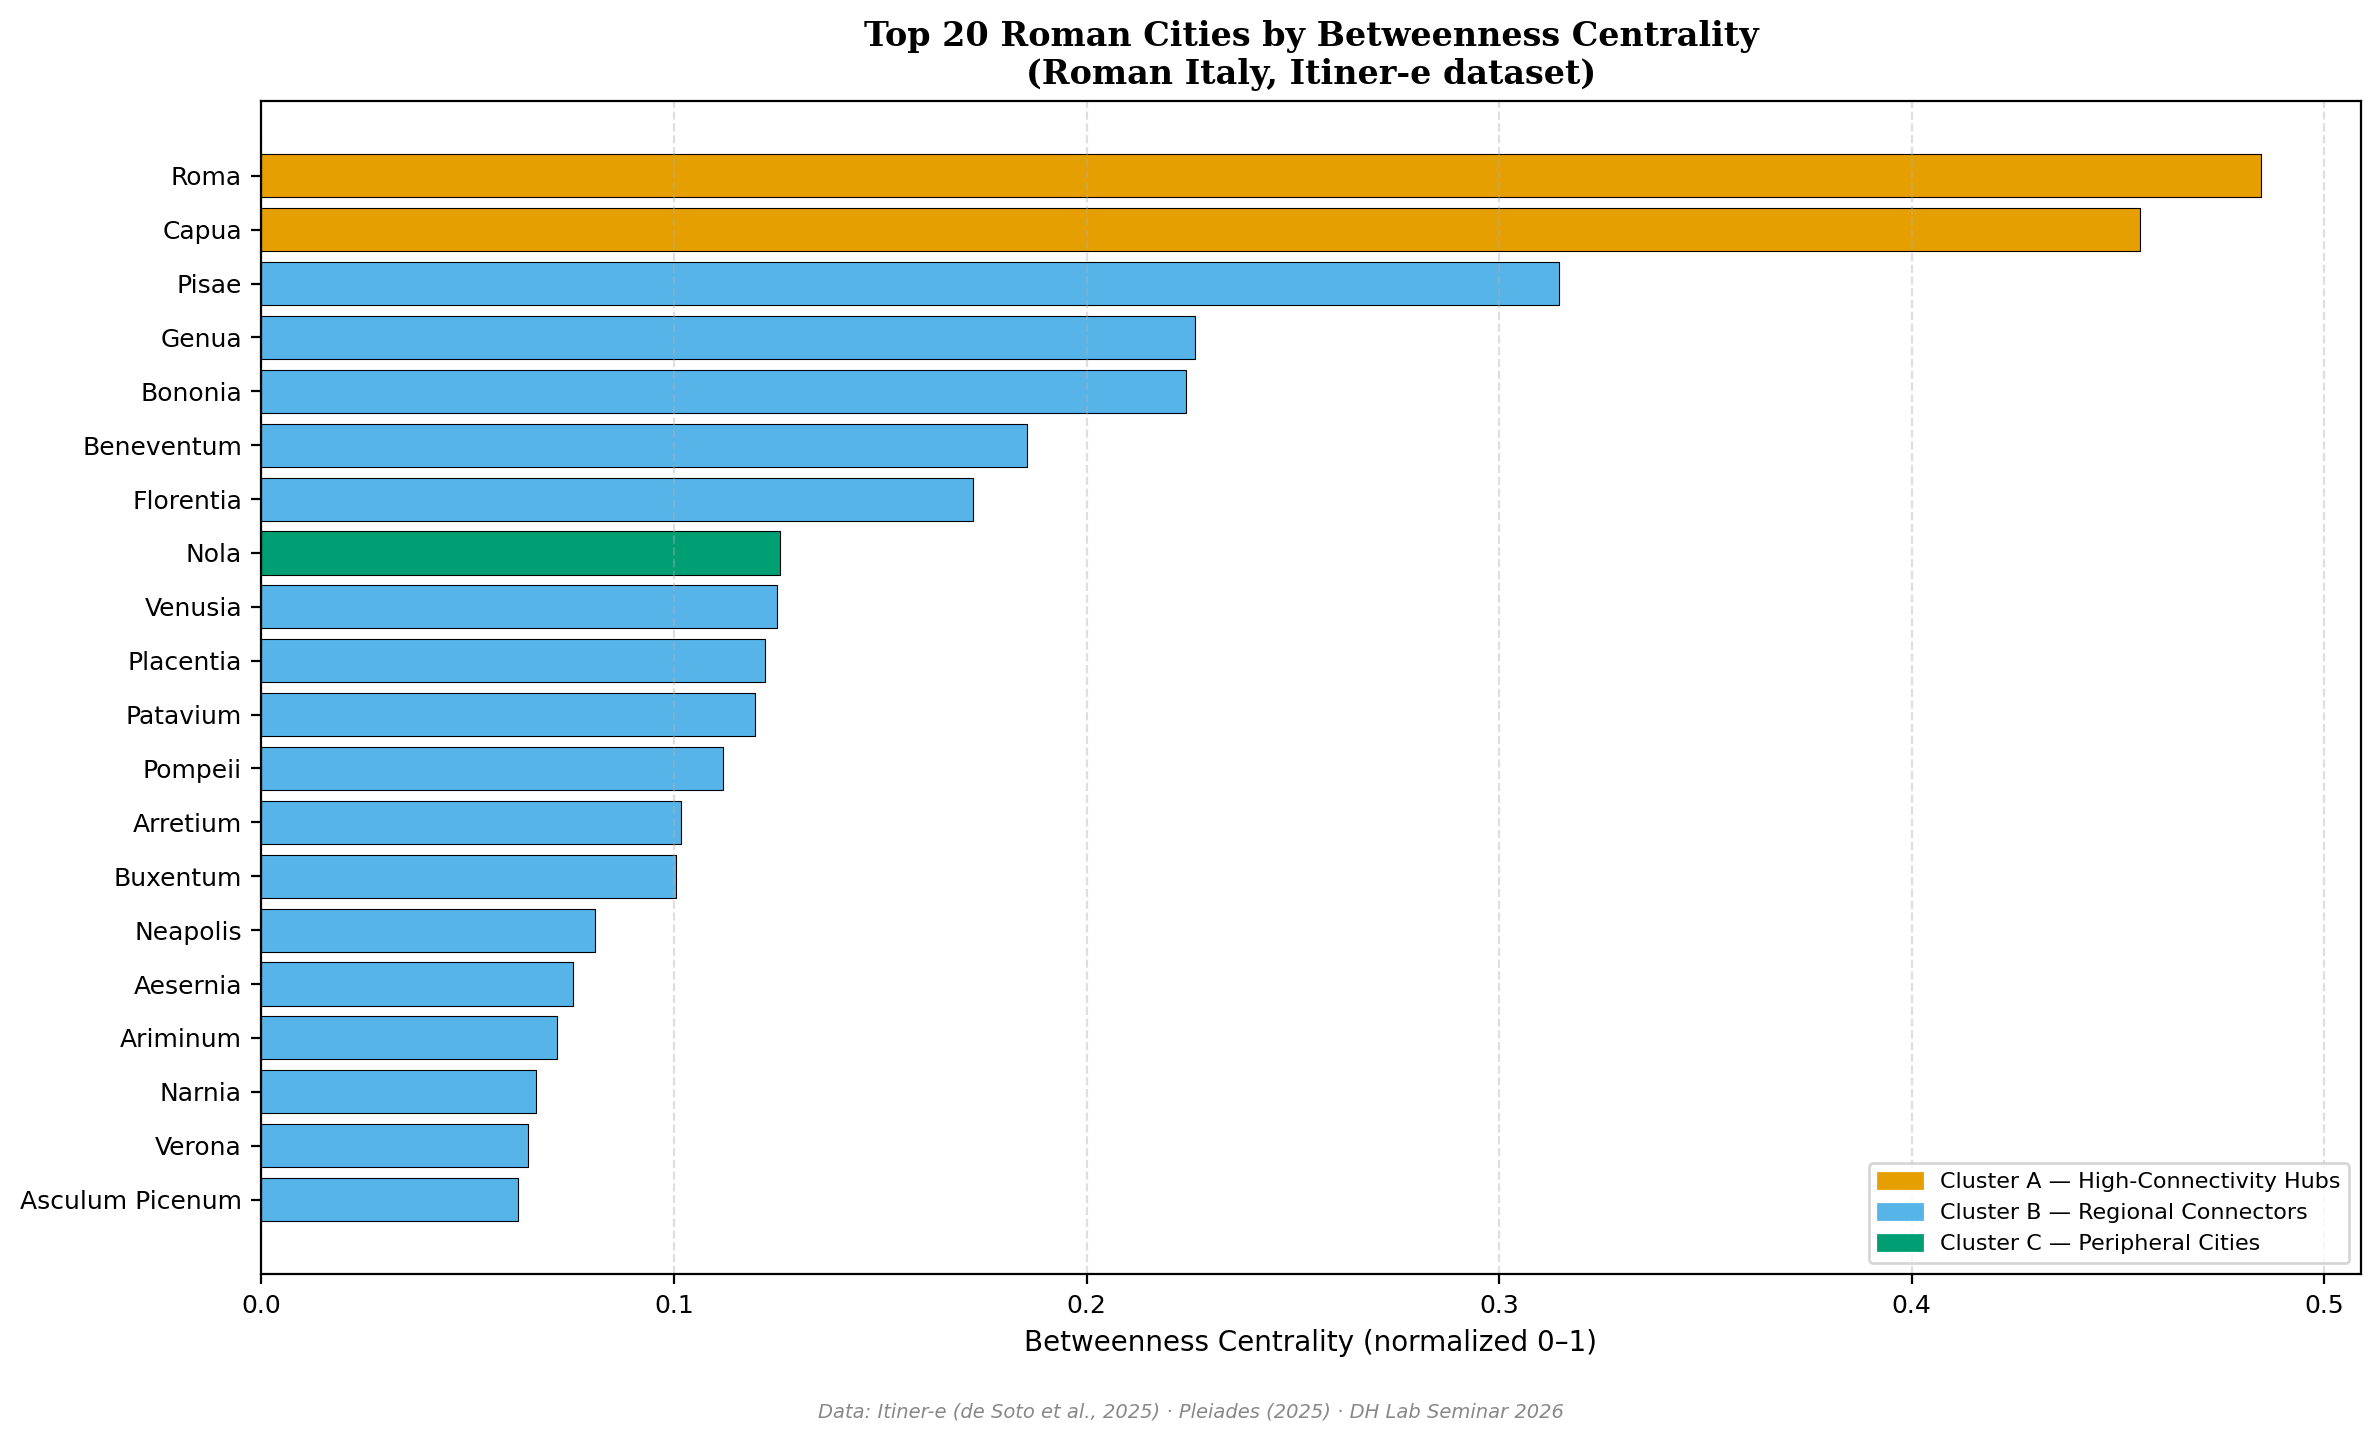

In [47]:
# ── Stage 5d: Centrality Bar Chart by Cluster ──────────────────────────────────
chart_path = OUT_DIR / 'centrality_chart.png'
create_centrality_chart(clustered_df, chart_path)
print(f'✓ Centrality chart saved to {chart_path}')

from IPython.display import Image
Image(str(chart_path))


---
## Results & Historical Interpretation

### 1. The Primacy of Rome and Capua
- **Roma ($C_B = 0.4845, C_D = 0.1364$, Rank #1):** Empirically confirms the historical proverb *omnes viae Romam ducunt* (*"all roads lead to Rome"*). Rome served as the primary origin point for the consular trunk highways (*Via Appia, Via Flaminia, Via Aurelia, Via Latina*).
- **Capua ($C_B = 0.4554, C_D = 0.1364$, Rank #2):** Functions as the indispensable transit gateway connecting Latium and Central Italy to Southern Italy (Apulia, Lucania, Calabria).

### 2. The Three Functional Archetypes
- **Cluster A — Macro-Hubs (2 cities, 4.4%):** Roma & Capua. Elite betweenness ($C_B \ge 0.45$) and degree ($k=6$).
- **Cluster B — Regional Connectors (24 cities, 53.3%):** Critical transit crossroads maintaining peninsular cohesion (e.g., *Bononia, Verona, Pisae, Genua, Florentia*).
- **Cluster C — Peripheral & Maritime Termini (19 cities, 42.2%):** Regional road endpoints ($C_B \le 0.03$).

### 3. Digital Humanities Critical Reflection: The "Port City Paradox"
Major Mediterranean commercial hubs—such as **Ostia** (port of Rome), **Puteoli** (Alexandrian grain terminal), and **Brundisium** (gateway to Greece)—cluster in **Cluster C (Peripheral)** with $C_B \approx 0.0000$.  
This is not an error in the machine learning model, but a critical methodological limitation of terrestrial-only graph models: ancient Roman commerce relied overwhelmingly on maritime transit (10×–60× cheaper than overland ox-cart freight). Because maritime routes are omitted, coastal ports appear mathematically as dead-end leaf nodes.
